In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Simple function: f(x) = x² 
# Minimum is at x=0, f(0)=0
# We'll use gradient descent to find that minimum

In [3]:
def f(x):
    return x**2

In [4]:
def gradient(x):
    return 2*x  # derivative of x² is 2x

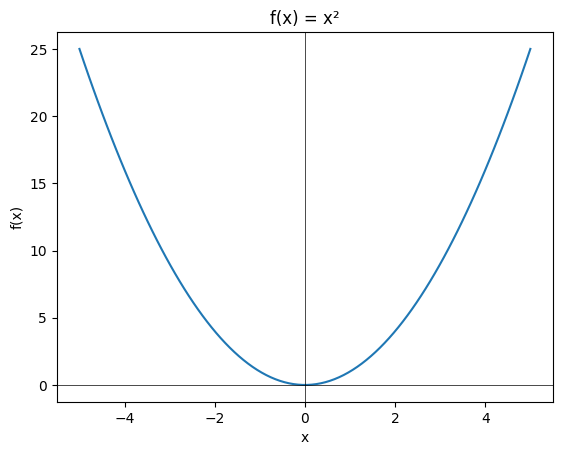

In [5]:
x = np.linspace(-5, 5, 100)
plt.plot(x, f(x))
plt.title("f(x) = x²")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.show()

Why do you think we use x² as our example function?

Simple reason — x² is the simplest function with a clear minimum, and its derivative (the gradient) is just 2x, easy to compute by hand.

In ML, your loss function (like MSE) is also U-shaped — high loss when predictions are wrong, low loss when predictions are good. Finding the bottom of that U = finding the best model weights.

So x² is a perfect toy example before we move to real loss functions.


In [6]:
# Starting point - random position on the curve
x = 5.0  # start at x=5 (far from minimum)
learning_rate = 0.1  # how big each step is
n_iterations = 50

In [7]:
# Store history to visualize later
history_x = [x]
history_f = [f(x)]

In [8]:
for i in range(n_iterations):
    grad = gradient(x)  # compute slope at current x
    x = x - learning_rate * grad  # step in opposite direction of slope
    history_x.append(x)
    history_f.append(f(x))
    
    if i % 10 == 0:
        print(f"Iteration {i}: x={x:.4f}, f(x)={f(x):.4f}")

print(f"\nFinal: x={x:.4f}, f(x)={f(x):.4f}")

Iteration 0: x=4.0000, f(x)=16.0000
Iteration 10: x=0.4295, f(x)=0.1845
Iteration 20: x=0.0461, f(x)=0.0021
Iteration 30: x=0.0050, f(x)=0.0000
Iteration 40: x=0.0005, f(x)=0.0000

Final: x=0.0001, f(x)=0.0000


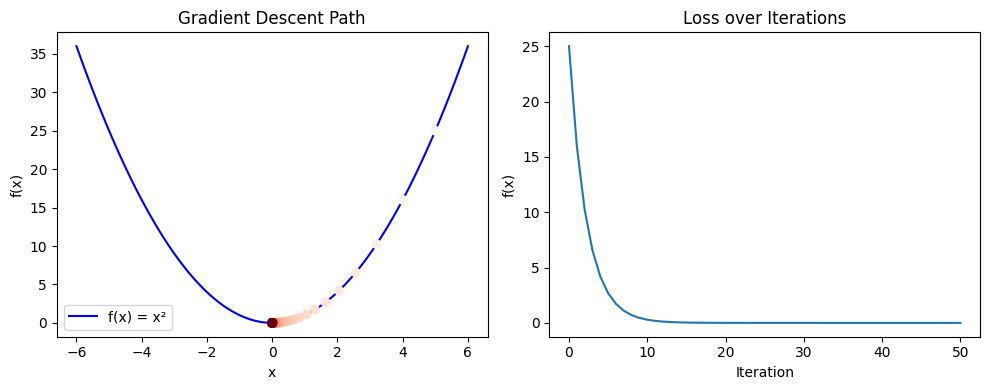

In [9]:
plt.figure(figsize=(10, 4))

# Left plot - path on the curve
plt.subplot(1, 2, 1)
x_range = np.linspace(-6, 6, 100)
plt.plot(x_range, f(x_range), 'b-', label='f(x) = x²')
plt.scatter(history_x, history_f, c=range(len(history_x)), cmap='Reds', zorder=5)
plt.title("Gradient Descent Path")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()

# Right plot - loss over iterations
plt.subplot(1, 2, 2)
plt.plot(history_f)
plt.title("Loss over Iterations")
plt.xlabel("Iteration")
plt.ylabel("f(x)")

plt.tight_layout()
plt.show()

Left plot (U-shape): shows the actual path gradient descent took down the parabola. The dots start at x=5 (top right) and cluster toward the bottom as it converges. The dots get darker red as iterations progress — you can see it reaching the minimum quickly.


Right plot (L-shape): shows the loss value over iterations. Starts high at f(5)=25, drops steeply in the first few iterations, then flattens out near 0. That L-shape is what you want to see when training any ML model — rapid initial improvement, then convergence.


In real ML training, this right plot is called the loss curve or training curve. You'll look at this after every model you train to check if it's learning properly.

Most important concept in gradient descent — learning rate. It controls how big each step is. 

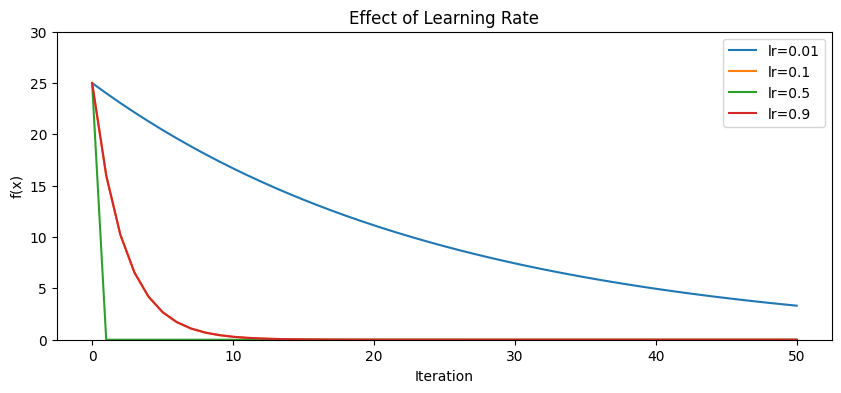

In [10]:
def run_gd(start_x, learning_rate, n_iterations):
    x = start_x
    history = [f(x)]
    for i in range(n_iterations):
        x = x - learning_rate * gradient(x)
        history.append(f(x))
    return history

plt.figure(figsize=(10, 4))

for lr in [0.01, 0.1, 0.5, 0.9]:
    history = run_gd(5.0, lr, 50)
    plt.plot(history, label=f'lr={lr}')

plt.title("Effect of Learning Rate")
plt.xlabel("Iteration")
plt.ylabel("f(x)")
plt.legend()
plt.ylim(0, 30)
plt.show()

Too small (0.01): takes tiny steps, converges very slowly — loss decreases but takes many more iterations to reach the minimum. Gets there eventually but inefficient.

Too large (0.9): takes huge steps, might overshoot the minimum — jumps back and forth across the bottom of the U, struggles to settle. Can even diverge (get worse) if extreme enough.

Sweet spot (0.1): reaches the minimum quickly and smoothly — that's what we used earlier.

0.01 (almost straight line) — taking tiny steps, loss barely decreasing over 50 iterations. Still far from minimum at the end. Too slow.

0.1 (L-shape) — this is actually the ideal one. Drops fast and converges cleanly. That's your sweet spot.

0.9 (L-shape but different) — converges fast but probably overshooting slightly before settling. Still works but less stable than 0.1.

0.5 (can't see) — likely overlapping with 0.9 or 0.1 since it's also a reasonable learning rate. They're probably sitting on top of each other.

The key takeaway:

Learning                                  RateBehavior

Too small (0.01)  -                      Slow, needs many iterations

Just right (0.1)   -                     Fast, stable convergence

Too large           -                    Overshoots, unstable

Extremely large      -                   Diverges completely

This is one of the most important practical decisions in ML — choosing the right learning rate. Too small and training takes forever. Too large and the model never converges. Finding the sweet spot is part of what's called **hyperparameter tuning**

Gradient descent **minimizes** the loss function by iteratively taking small steps in the direction that reduces the error most. It's not just calculating — it's actively finding the lowest point.